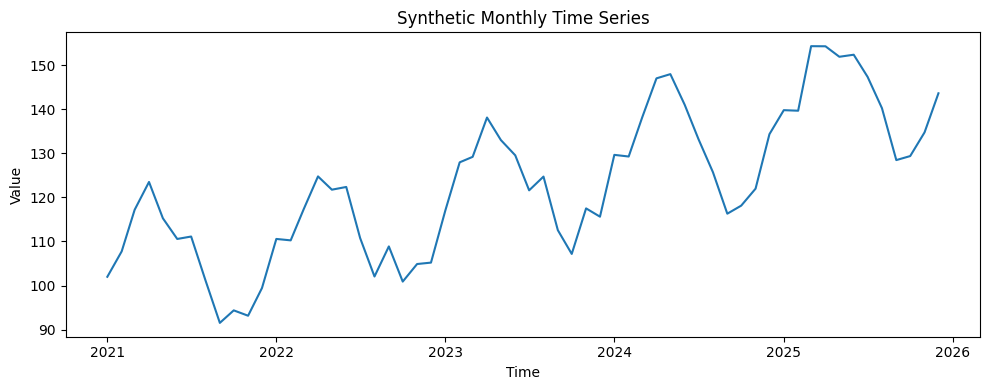

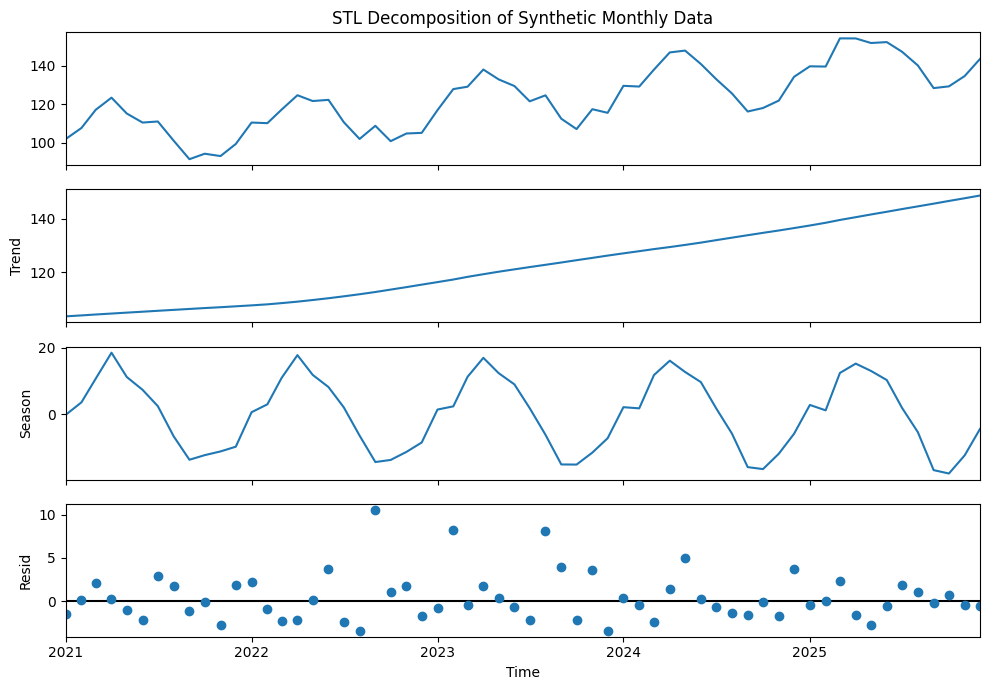

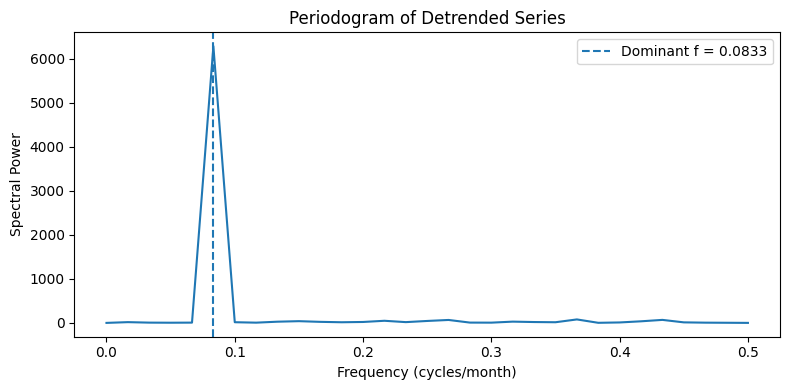

Dominant frequency: 0.0833 cycles/month
Dominant period: 12.0 months


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL
from scipy.signal import periodogram
import matplotlib.dates as mdates


# GENERATE SYNTHETIC MONTHLY DATA


np.random.seed(42)

n = 60                    # 60 months = 5 years
t = np.arange(n)

# Trend component
trend = 100 + 0.8 * t

# Seasonal component: repeats every 12 months
seasonal = 15 * np.sin(2 * np.pi * t / 12)

# Random noise
noise = np.random.normal(
    loc=0,
    scale=4,
    size=n
)

# Observed series
y = trend + seasonal + noise

# Monthly dates
dates = pd.date_range(
    start="2021-01-01",
    periods=n,
    freq="MS"
)

data = pd.Series(
    y,
    index=dates,
    name="Value"
)


#PLOT ORIGINAL TIME SERIES


plt.figure(figsize=(10, 4))

plt.plot(data)

plt.title("Synthetic Monthly Time Series")
plt.xlabel("Time")
plt.ylabel("Value")

plt.tight_layout()
plt.show()


#STL DECOMPOSITION


stl = STL(
    data,
    period=12,
    seasonal=13,
    robust=True
)

result = stl.fit()

fig = result.plot()

# Increase figure size
fig.set_size_inches(10, 7)

# Format x-axis
for ax in fig.axes:
    ax.xaxis.set_major_locator(
        mdates.YearLocator()
    )
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

fig.axes[0].set_title(
    "STL Decomposition of Synthetic Monthly Data"
)

fig.axes[-1].set_xlabel("Time")

plt.tight_layout()
plt.show()


# SPECTRAL ANALYSIS

# Remove estimated trend
detrended = data - result.trend

freq, power = periodogram(detrended)

# Find dominant frequency
index = np.argmax(power[1:]) + 1

dominant_frequency = freq[index]
dominant_period = 1 / dominant_frequency


# PLOT PERIODOGRAM


plt.figure(figsize=(8, 4))

plt.plot(freq, power)

# Mark dominant frequency
plt.axvline(
    dominant_frequency,
    linestyle="--",
    label=f"Dominant f = {dominant_frequency:.4f}"
)

plt.xlabel("Frequency (cycles/month)")
plt.ylabel("Spectral Power")
plt.title("Periodogram of Detrended Series")

plt.legend()
plt.tight_layout()
plt.show()


# PRINT DOMINANT PERIOD


print(
    "Dominant frequency:",
    round(dominant_frequency, 4),
    "cycles/month"
)

print(
    "Dominant period:",
    round(dominant_period, 2),
    "months"
)

# Periodogram Analysis: Seasonal Patterns in the Frequency Domain

**Objective:** reproduce the original monthly-series analysis, detect two periodic components, study noise, and compare raw versus detrended spectra.

The original baseline cell is retained. The experiments below use a fixed random seed so that the plots and detected values are reproducible. Frequencies are measured in **cycles per month**, so the corresponding period is `1 / frequency` months.

## 1. Baseline interpretation

The first cell reproduces the supplied 60-month synthetic series, STL decomposition, trend removal, periodogram, and dominant-frequency / dominant-period calculations.

**Interpretation:** a frequency near `1/12 ≈ 0.0833 cycles/month` represents a pattern repeating every 12 months. Its reciprocal, `1 / frequency`, is the period in months. The strongest non-zero peak is treated as the dominant periodic component; the zero-frequency (DC) component is excluded because it represents the mean level, not a repeating cycle.

In [2]:
# Baseline values from the supplied code
print(f"Expected annual frequency: {1/12:.4f} cycles/month")
print(f"Detected dominant frequency: {dominant_frequency:.4f} cycles/month")
print(f"Detected dominant period: {dominant_period:.2f} months")
print("A detected period near 12 months supports the intended annual seasonality.")

Expected annual frequency: 0.0833 cycles/month
Detected dominant frequency: 0.0833 cycles/month
Detected dominant period: 12.00 months
A detected period near 12 months supports the intended annual seasonality.


## 2. Add a second periodic component (12 months + 6 months)

We retain the 12-month sinusoid and add a 6-month sinusoid. The data also contains a linear trend and random noise. For this experiment, the known linear trend is removed before calculating the periodogram so it does not dominate the spectrum. With 60 observations, both 12-month and 6-month periods align with Fourier frequency bins.

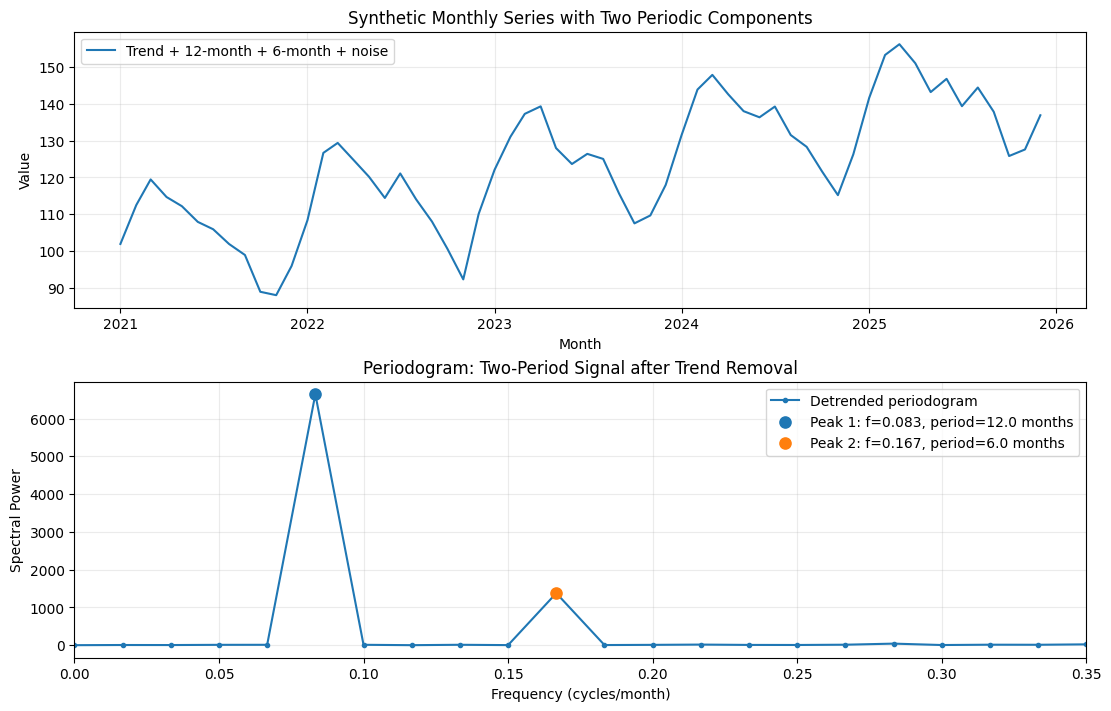

Two strongest non-zero local peaks:
1. frequency = 0.0833 cycles/month; period = 12.00 months; power = 6643.94
2. frequency = 0.1667 cycles/month; period = 6.00 months; power = 1377.06
Expected periods: 12 months (f=0.0833) and 6 months (f=0.1667).


In [3]:
# Reproducible two-season signal
np.random.seed(2026)
n2 = 60
t2 = np.arange(n2)
dates2 = pd.date_range("2021-01-01", periods=n2, freq="MS")

trend2 = 100 + 0.8 * t2
season_12 = 15 * np.sin(2 * np.pi * t2 / 12)
season_6 = 7 * np.sin(2 * np.pi * t2 / 6 + 0.4)
noise2 = np.random.normal(0, 2, n2)
two_period_signal = trend2 + season_12 + season_6 + noise2
two_period_series = pd.Series(two_period_signal, index=dates2, name="Two-period signal")

# Remove the known linear trend, leaving both periodic components and noise.
two_period_detrended = two_period_series - trend2
freq2, power2 = periodogram(two_period_detrended.to_numpy())

# Find local spectral peaks, excluding zero frequency; report the two strongest.
from scipy.signal import find_peaks
peak_indices, _ = find_peaks(power2)
peak_indices = peak_indices[freq2[peak_indices] > 0]
strongest_two = peak_indices[np.argsort(power2[peak_indices])[-2:]][::-1]
detected = [(freq2[i], 1 / freq2[i], power2[i]) for i in strongest_two]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True)
axes[0].plot(two_period_series.index, two_period_series.values, label="Trend + 12-month + 6-month + noise")
axes[0].set_title("Synthetic Monthly Series with Two Periodic Components")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Value")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(freq2, power2, marker="o", markersize=3, label="Detrended periodogram")
for rank, i in enumerate(strongest_two, start=1):
    axes[1].scatter(freq2[i], power2[i], s=65, zorder=3, label=f"Peak {rank}: f={freq2[i]:.3f}, period={1/freq2[i]:.1f} months")
axes[1].set_xlim(0, 0.35)
axes[1].set_title("Periodogram: Two-Period Signal after Trend Removal")
axes[1].set_xlabel("Frequency (cycles/month)")
axes[1].set_ylabel("Spectral Power")
axes[1].legend()
axes[1].grid(alpha=0.25)
plt.show()

print("Two strongest non-zero local peaks:")
for rank, (f, period, pwr) in enumerate(detected, start=1):
    print(f"{rank}. frequency = {f:.4f} cycles/month; period = {period:.2f} months; power = {pwr:.2f}")

# The expected frequencies are 1/12 = 0.0833 and 1/6 = 0.1667 cycles/month.
# Their reciprocal periods should be close to 12 and 6 months, respectively.
print(f"Expected periods: 12 months (f={1/12:.4f}) and 6 months (f={1/6:.4f}).")


## 3. Effect of noise on spectral detection

The underlying 12-month and 6-month components are held fixed while only the noise standard deviation changes (0.5, 3, and 8). The linear trend is removed consistently in all three cases. Higher noise generally raises the background spectral power and makes the periodic peaks less distinct relative to that background.

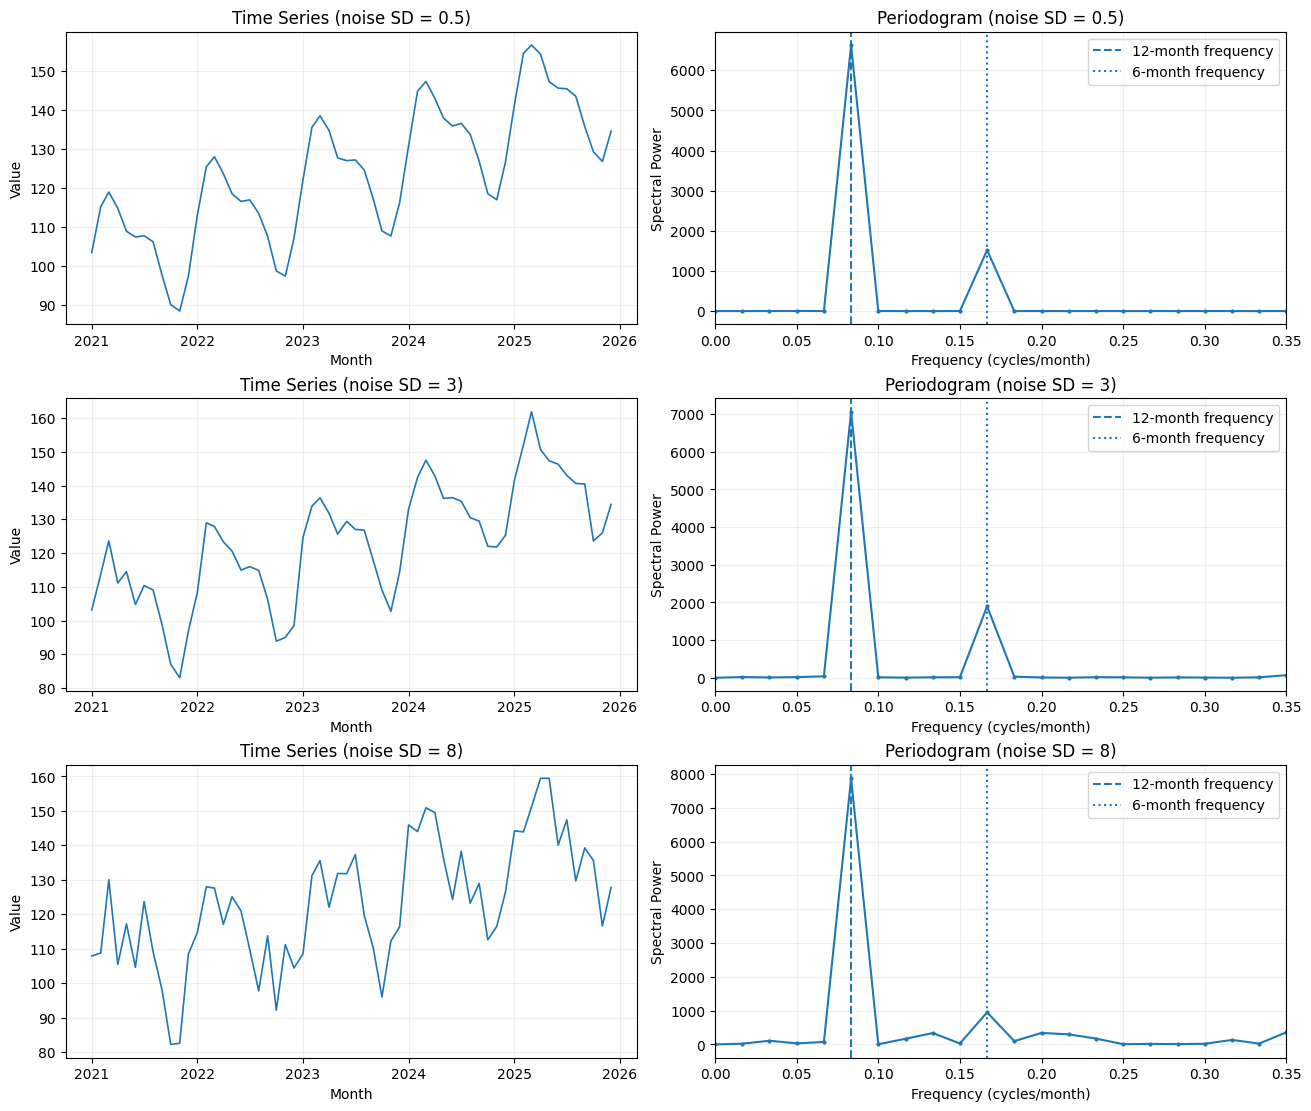

Noise SD 0.5: power at 12-month frequency =  6631.26; power at 6-month frequency =  1518.30
Noise SD   3: power at 12-month frequency =  7066.65; power at 6-month frequency =  1898.45
Noise SD   8: power at 12-month frequency =  7870.10; power at 6-month frequency =   948.04


In [4]:
# Same periodic signal, different noise levels; fixed seed ensures reproducibility.
rng = np.random.default_rng(20261012)
noise_levels = [0.5, 3, 8]
noise_results = {}

fig, axes = plt.subplots(len(noise_levels), 2, figsize=(13, 11), constrained_layout=True)
for row, sigma in enumerate(noise_levels):
    noisy = trend2 + season_12 + season_6 + rng.normal(0, sigma, n2)
    noisy_series = pd.Series(noisy, index=dates2, name=f"Noise SD {sigma}")
    noisy_detrended = noisy - trend2
    f_noise, p_noise = periodogram(noisy_detrended)
    noise_results[sigma] = (noisy_series, f_noise, p_noise)

    axes[row, 0].plot(dates2, noisy_series, linewidth=1.2)
    axes[row, 0].set_title(f"Time Series (noise SD = {sigma})")
    axes[row, 0].set_xlabel("Month")
    axes[row, 0].set_ylabel("Value")
    axes[row, 0].grid(alpha=0.2)

    axes[row, 1].plot(f_noise, p_noise, marker=".", markersize=4)
    axes[row, 1].axvline(1/12, linestyle="--", label="12-month frequency")
    axes[row, 1].axvline(1/6, linestyle=":", label="6-month frequency")
    axes[row, 1].set_xlim(0, 0.35)
    axes[row, 1].set_title(f"Periodogram (noise SD = {sigma})")
    axes[row, 1].set_xlabel("Frequency (cycles/month)")
    axes[row, 1].set_ylabel("Spectral Power")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.2)
plt.show()

for sigma, (_, f_noise, p_noise) in noise_results.items():
    i12 = np.argmin(np.abs(f_noise - 1/12))
    i6 = np.argmin(np.abs(f_noise - 1/6))
    print(f"Noise SD {sigma:>3}: power at 12-month frequency = {p_noise[i12]:8.2f}; "
          f"power at 6-month frequency = {p_noise[i6]:8.2f}")

# The periodic frequencies stay fixed because the signal components do not change.
# Increasing noise makes the peaks less prominent against the noisier spectral background;
# at high noise, it becomes harder to distinguish true periodic peaks from random variation.


## 4. Raw versus detrended spectral analysis

Use the high-noise two-period dataset (noise SD = 8) as the selected example. The raw series includes a linear trend, while the detrended version subtracts the known trend. A trend contributes strong low-frequency power, which can obscure periodic peaks. Detrending helps make the 12-month and 6-month components easier to compare.

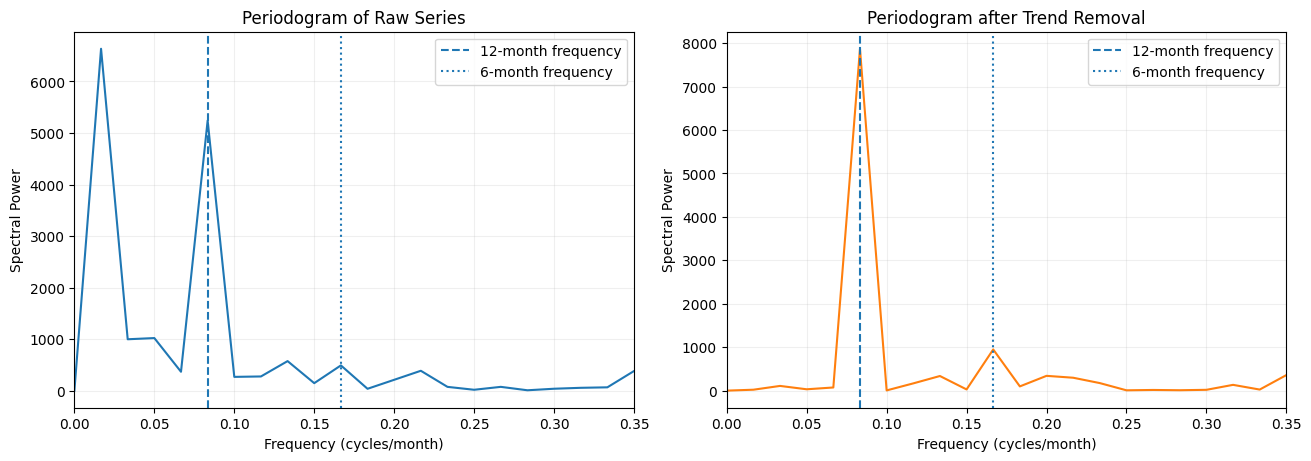

Raw-series power at the first non-zero frequency (0.0167 cycles/month): 6634.78
Detrended power at the same frequency: 21.06


In [5]:
selected_raw = noise_results[8][0].to_numpy()
selected_detrended = selected_raw - trend2
f_raw, p_raw = periodogram(selected_raw)
f_det, p_det = periodogram(selected_detrended)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
axes[0].plot(f_raw, p_raw, color="tab:blue")
axes[0].axvline(1/12, linestyle="--", label="12-month frequency")
axes[0].axvline(1/6, linestyle=":", label="6-month frequency")
axes[0].set_xlim(0, 0.35)
axes[0].set_title("Periodogram of Raw Series")
axes[0].set_xlabel("Frequency (cycles/month)")
axes[0].set_ylabel("Spectral Power")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(f_det, p_det, color="tab:orange")
axes[1].axvline(1/12, linestyle="--", label="12-month frequency")
axes[1].axvline(1/6, linestyle=":", label="6-month frequency")
axes[1].set_xlim(0, 0.35)
axes[1].set_title("Periodogram after Trend Removal")
axes[1].set_xlabel("Frequency (cycles/month)")
axes[1].set_ylabel("Spectral Power")
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.show()

print(f"Raw-series power at the first non-zero frequency ({f_raw[1]:.4f} cycles/month): {p_raw[1]:.2f}")
print(f"Detrended power at the same frequency: {p_det[1]:.2f}")
# The raw spectrum contains strong low-frequency energy from the upward trend.
# Removing the trend reduces this slow-varying contribution and makes seasonal peaks easier to interpret.


## 5. Final summary and interpretation

### Main frequencies and periods
- **Baseline:** the original signal was generated with a 12-month seasonal component. Its expected frequency is `1/12 = 0.0833 cycles/month`; the detected dominant period should be near 12 months.
- **Two-period experiment:** expected frequencies are `0.0833 cycles/month` (12 months) and `0.1667 cycles/month` (6 months). The printed peak table above reports the two strongest local spectral peaks and their reciprocal periods.
- **Noise experiment:** the frequencies of the true components remain the same at all noise levels because the underlying sinusoids do not change.
- **Raw versus detrended:** the raw spectrum includes low-frequency power associated with the linear trend; detrending makes the periodic components more interpretable.

### Evidence-based observations
1. In the two-period signal, the periodogram shows peaks around the expected frequencies for 12-month and 6-month repetition, and the reciprocal-frequency calculations convert those peaks back to months.
2. With low noise (SD = 0.5), periodic peaks are expected to stand out most clearly because random variation is small relative to the seasonal amplitudes.
3. As noise increases from SD 0.5 to 3 to 8, the time series becomes more irregular and the spectral background becomes more variable, so the true peaks are harder to identify visually.
4. The raw-series periodogram has additional low-frequency energy due to the linear trend. Removing that trend reduces the influence of slow drift and helps focus the interpretation on repeating patterns.
5. The easiest case is the low-noise two-period experiment; the hardest is the high-noise case, where random fluctuations can make peaks less distinct.

**Conclusion:** a periodogram reveals repeating behavior as peaks at characteristic frequencies. Converting frequency to period using `period = 1 / frequency` links those peaks to interpretable cycle lengths. Trend removal and noise level both affect how clearly the cycles can be identified.